# Niveles vibracionales del I$_2$ por absorción UV-vis — Laboratorio 3

Espectro de absorción de I$_2$ gaseoso (Shimadzu UV-1650, 500–700 nm). El I$_2$ es homonuclear y no absorbe en el IR, así que sus niveles vibracionales se obtienen de la **estructura fina de la transición electrónica X → B**: cada pico es una transición X($v''$) → B($v'$).

Para cada línea
$$\tilde\nu(n',n'') = a(n'') + b\left(n'+\tfrac12\right) + c\left(n'+\tfrac12\right)^2,\qquad
a(n'') = \tilde\nu_{el} - \omega''\left(n''+\tfrac12\right) + \omega''x''\left(n''+\tfrac12\right)^2,\quad b=\omega',\ c=-\omega'x'$$
y el objetivo es: (1) graficar la absorbancia, (2) evaluar el filtro pasa bajos, (3) encontrar las series de transiciones y determinar $a(n''=0,1,2)$, $b$ y $c$, y (4) obtener de ahí los parámetros de Morse de los estados X y B.

Los números de onda $\tilde\nu$ están en cm$^{-1}$.

# Importando datos

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path
from scipy.signal import butter, filtfilt, find_peaks, peak_prominences
from scipy.optimize import curve_fit

In [2]:
DATA_DIR = Path("datos_I2")

def leer_2022(nombre):
    # .txt del espectrómetro: "lambda<TAB>A", algunos con 2 líneas de encabezado entre comillas
    df = pd.read_csv(DATA_DIR / "2022" / nombre, sep="\t", header=None, names=["lambda", "A"], on_bad_lines="skip")
    return df.apply(pd.to_numeric, errors="coerce").dropna().reset_index(drop=True)

def leer_2025():
    # El .dat de 2025 trae transmitancia en % (coma decimal): A = -log10(T/100) = log10(I0/I)
    df = pd.read_csv(DATA_DIR / "2025" / "DATOS_I2_2025.dat", sep="\t", decimal=",", header=0, names=["lambda", "T"])
    df["A"] = -np.log10(df["T"] / 100)
    return df[["lambda", "A"]]

ancho = leer_2022("Iodo 250700.txt")   # barrido ancho 250-700 nm, paso 2 nm
alta = leer_2022("Iodo BR.txt")        # 500-700 nm, paso 0.05 nm
media = leer_2022("iodo MR.txt")       # 500-700 nm, paso 0.1 nm
d25 = leer_2025()                      # 500-650 nm, paso 0.1 nm

resumen = pd.DataFrame({
    nombre: {"puntos": len(df), "lambda min (nm)": df["lambda"].min(), "lambda max (nm)": df["lambda"].max(),
             "paso (nm)": df["lambda"].diff().median()}
    for nombre, df in {"2022 ancho": ancho, "2022 BR": alta, "2022 MR": media, "2025": d25}.items()
}).T
resumen

,puntos,lambda min (nm),lambda max (nm),paso (nm)
2022 ancho,226.0,250.0,700.0,2.00
2022 BR,4001.0,500.0,700.0,0.05
2022 MR,2001.0,500.0,700.0,0.10
2025,1501.0,500.0,650.0,0.10


# Visualización de los espectros (A = log$_{10}(I_0/I)$)

Hay cuatro archivos. El de 2025 es el que se usa como dato principal (paso 0.1 nm, resuelve las líneas); el `BR` de 2022 se usa como verificación independiente y el `MR` sólo para mostrar el efecto de la resolución. El barrido ancho muestra la banda de transferencia de carga (~320 nm) y la banda X → B (~500 nm).

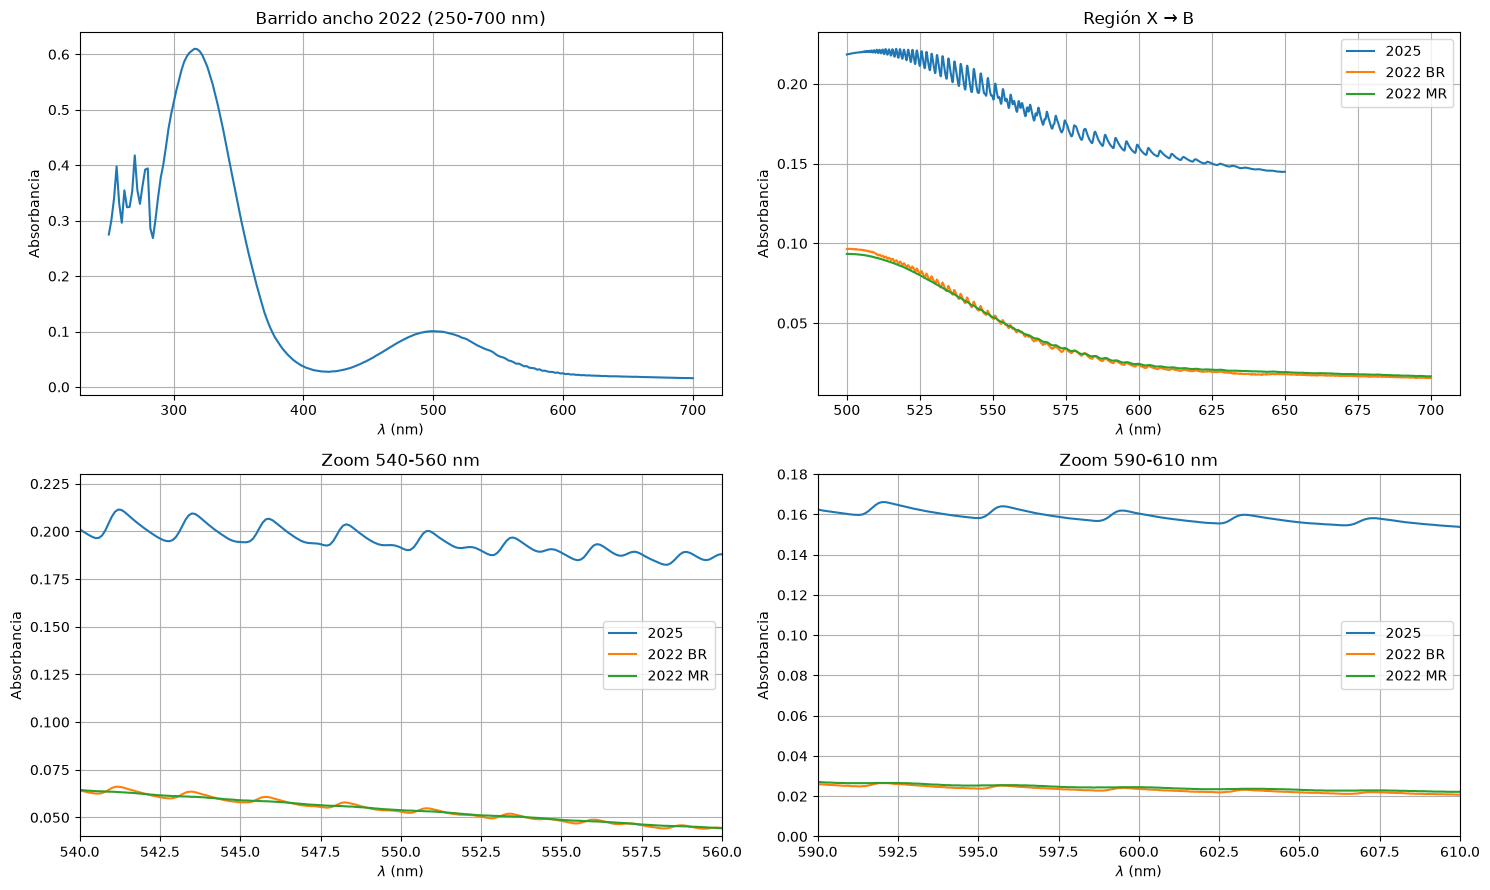

In [3]:
fig, axs = plt.subplots(2, 2, figsize=(15, 9))

axs[0, 0].plot(ancho["lambda"], ancho["A"])
axs[0, 0].set_title("Barrido ancho 2022 (250-700 nm)")

for df, nombre in [(d25, "2025"), (alta, "2022 BR"), (media, "2022 MR")]:
    axs[0, 1].plot(df["lambda"], df["A"], label=nombre)
    axs[1, 0].plot(df["lambda"], df["A"], label=nombre)
    axs[1, 1].plot(df["lambda"], df["A"], label=nombre)
axs[0, 1].set_title("Región X → B")
axs[1, 0].set_xlim(540, 560); axs[1, 0].set_ylim(0.04, 0.23); axs[1, 0].set_title("Zoom 540-560 nm")
axs[1, 1].set_xlim(590, 610); axs[1, 1].set_ylim(0.0, 0.18); axs[1, 1].set_title("Zoom 590-610 nm")

for ax in axs.flat:
    ax.set_xlabel(r"$\lambda$ (nm)"); ax.set_ylabel("Absorbancia"); ax.grid(True)
for ax in axs.flat[1:]:
    ax.legend()
plt.tight_layout()
plt.show()

Observaciones:

- Los espectros de 2025 y 2022 tienen la misma estructura de picos pero **distinto nivel de absorbancia** (≈0.15–0.22 en 2025 contra ≈0.02–0.10 en 2022): los archivos no dicen por qué (celda, cantidad de vapor, línea base), pero no cambia la posición de las líneas, que es lo que se usa.
- `MR` (2022, paso 0.1 nm) **no resuelve** la estructura vibracional: es prácticamente una curva suave. `BR` y 2025 sí la resuelven. Por eso se trabaja con 2025 y `BR`.
- La banda X → B es una envolvente ancha (máximo ~500 nm) con la progresión vibracional encima. La transición X → A no se ve: según la figura de la clase es unas 20 veces más débil que la B ← X ($\varepsilon\approx 40$ contra $\approx 650$ l/mol/cm) y queda tapada por la cola de la banda B en este rango.

# Pasaje a número de onda

La Morse se escribe en energía, así que se trabaja en $\tilde\nu = 10^7/\lambda$ (cm$^{-1}$, con $\lambda$ en nm). A 600 nm, un paso de 0.1 nm equivale a ≈ 2.8 cm$^{-1}$, que es comparable al error que se espera en las posiciones; por eso conviene refinar la posición de cada pico por debajo del paso de muestreo.

paso = 0.10 nm  ->  d(nu) a 600 nm = 2.78 cm-1


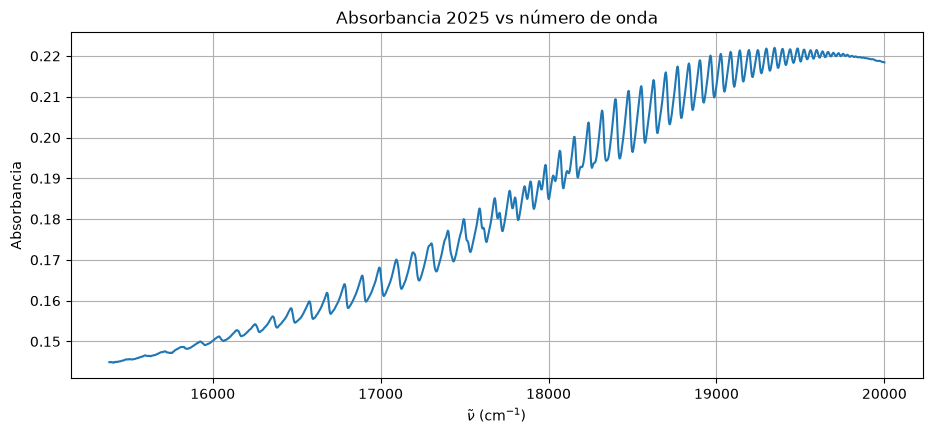

In [4]:
l25 = d25["lambda"].to_numpy()
A25 = d25["A"].to_numpy()
paso = l25[1] - l25[0]
print(f"paso = {paso:.2f} nm  ->  d(nu) a 600 nm = {1e7 / 600**2 * paso:.2f} cm-1")

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(1e7 / l25, A25)
ax.set_xlabel(r"$\tilde\nu$ (cm$^{-1}$)"); ax.set_ylabel("Absorbancia"); ax.grid(True)
ax.set_title("Absorbancia 2025 vs número de onda")
plt.show()

# Filtro pasa bajos

Se usa un Butterworth de orden 4 aplicado con `filtfilt` (fase cero, no desplaza los picos por construcción) sobre $A(\lambda)$, que está uniformemente muestreado. La frecuencia de corte $f_c$ está en ciclos/nm. La periodicidad de las líneas es de ≈ 2.5–4 nm, es decir $f\approx 0.3$ ciclos/nm, así que un corte demasiado bajo borra o desplaza las líneas.

Para evaluar el filtro (**¿afecta la energía?**) se toman las líneas bien aisladas con $\lambda > 568$ nm, se mide su posición con un ajuste local gaussiana + recta sobre los datos **crudos** y se compara con la posición del máximo (con interpolación parabólica) en el espectro filtrado para distintos $f_c$.

In [5]:
def pasa_bajos(A, paso, fc):
    # Butterworth orden 4 de fase cero; fc en ciclos/nm, la frecuencia de Nyquist es 1/(2*paso)
    b, a = butter(4, fc / (0.5 / paso))
    return filtfilt(b, a, A)

def refinar_picos(lam, A, idx):
    # interpolación parabólica de los 3 puntos alrededor de cada máximo (precisión por debajo del paso)
    y0, y1, y2 = A[idx - 1], A[idx], A[idx + 1]
    return lam[idx] + 0.5 * (y0 - y2) / (y0 - 2 * y1 + y2) * (lam[1] - lam[0])

def picos_filtrados(lam, A, fc, prom=3e-4):
    F = pasa_bajos(A, lam[1] - lam[0], fc)
    idx, _ = find_peaks(F, prominence=prom)
    idx = idx[(idx > 0) & (idx < len(F) - 1)]
    return F, idx, refinar_picos(lam, F, idx), peak_prominences(F, idx)[0]

def gauss_lineal(x, amp, c, sigma, fondo, pendiente):
    return amp * np.exp(-((x - c) ** 2) / (2 * sigma**2)) + fondo + pendiente * (x - c)

# Posición "de referencia": ajuste local gaussiana + recta sobre los datos crudos
idx_crudo, _ = find_peaks(A25, prominence=3e-4)
idx_ref = [i for i in idx_crudo if 568 < l25[i] < 625]
centros_ref = []
for i in idx_ref:
    m = np.abs(l25 - l25[i]) <= 0.7
    # centro acotado a +-0.3 nm y ancho a 0.15-1 nm para que el ajuste no se escape en las líneas más débiles
    lim = ([0, l25[i] - 0.3, 0.15, -np.inf, -np.inf], [np.inf, l25[i] + 0.3, 1.0, np.inf, np.inf])
    popt, _ = curve_fit(gauss_lineal, l25[m], A25[m], p0=[0.003, l25[i], 0.4, A25[i], 0.0], bounds=lim, maxfev=20000)
    centros_ref.append(popt[1])
centros_ref = np.array(centros_ref)
print(f"{len(centros_ref)} líneas de referencia entre 568 y 625 nm")

FCS = [0.4, 0.6, 0.8, 1.0, 1.5, 2.0, 3.0]
por_fc = {fc: picos_filtrados(l25, A25, fc) for fc in FCS}
lam_3, prom_3 = por_fc[3.0][2], por_fc[3.0][3]     # fc = 3 ciclos/nm: filtrado casi nulo, sirve de comparación

filas = []
for fc, (F, idx_f, lam_f, prom_f) in por_fc.items():
    d_ref, d_3, rel = [], [], []
    for c_ref in centros_ref:
        j, j3 = np.argmin(np.abs(lam_f - c_ref)), np.argmin(np.abs(lam_3 - c_ref))
        if abs(lam_f[j] - c_ref) < 0.5 and abs(lam_3[j3] - c_ref) < 0.5:
            d_ref.append(1e7 / lam_f[j] - 1e7 / c_ref)
            d_3.append(1e7 / lam_f[j] - 1e7 / lam_3[j3])
            rel.append(prom_f[j] / prom_3[j3])
    filas.append({"fc (ciclos/nm)": fc, "picos detectados": len(idx_f), "líneas recuperadas": len(d_ref),
                  "media vs ajuste crudo (cm-1)": np.mean(d_ref),
                  "media vs fc=3 (cm-1)": np.mean(d_3), "max |vs fc=3| (cm-1)": np.max(np.abs(d_3)),
                  "profundidad relativa": np.mean(rel)})
pd.DataFrame(filas).round(2)

16 líneas de referencia entre 568 y 625 nm


,fc (ciclos/nm),picos detectados,líneas recuperadas,media vs ajuste crudo (cm-1),media vs fc=3 (cm-1),max |vs fc=3| (cm-1),profundidad relativa
0,0.4,34,16,-9.74,-6.99,10.90,0.72
1,0.6,44,16,-6.78,-4.03,7.94,0.89
2,0.8,49,16,-5.08,-2.33,5.79,0.96
3,1.0,54,16,-4.02,-1.27,4.21,0.98
4,1.5,60,16,-3.00,-0.25,1.96,1.00
5,2.0,60,16,-2.87,-0.11,0.96,1.00
6,3.0,61,16,-2.75,0.00,0.00,1.00


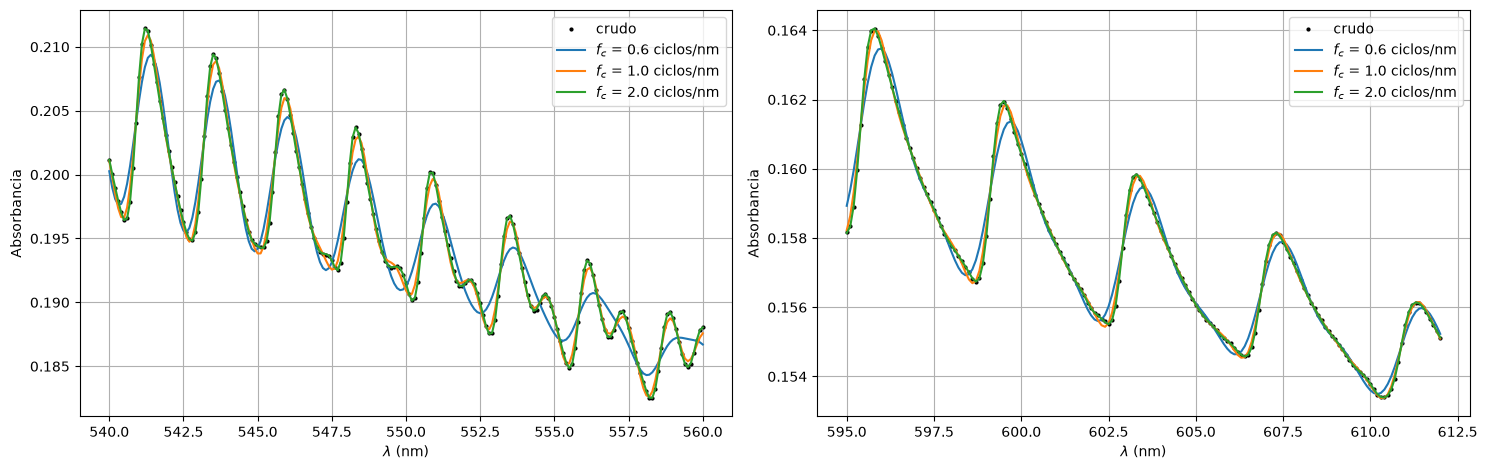

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(15, 4.8))
for ax, (lo, hi) in zip(axs, [(540, 560), (595, 612)]):
    m = (l25 >= lo) & (l25 <= hi)
    ax.plot(l25[m], A25[m], "k.", ms=4, label="crudo")
    for fc in [0.6, 1.0, 2.0]:
        ax.plot(l25[m], pasa_bajos(A25, paso, fc)[m], label=f"$f_c$ = {fc} ciclos/nm")
    ax.set_xlabel(r"$\lambda$ (nm)"); ax.set_ylabel("Absorbancia"); ax.grid(True); ax.legend()
plt.tight_layout()
plt.show()

**Resultado.** Con $f_c \ge 1.5$ ciclos/nm la posición de las líneas casi no cambia respecto de $f_c = 3$ (corrimiento medio 0.1–0.25 cm$^{-1}$, máximo ≈ 2 cm$^{-1}$ a 1.5 y < 1 cm$^{-1}$ a 2.0) y la profundidad de los picos se conserva. Con cortes bajos ($f_c \le 1$) el filtro **sí afecta la energía**: los picos se corren hacia menor $\tilde\nu$ (−1 a −7 cm$^{-1}$ en media), se achatan (72 % de la profundidad con $f_c=0.4$) y se pierden líneas (34 picos contra 61). Se adopta $f_c = 2$ ciclos/nm: el corrimiento (< 1 cm$^{-1}$) es menor que el error final de las posiciones (≈ 3 cm$^{-1}$).

La columna "vs ajuste crudo" da ≈ −2.8 cm$^{-1}$ incluso con $f_c=3$, o sea que **no es un efecto del filtro**: el máximo aparente de la curva está corrido respecto del centro de la gaussiana ajustada porque la línea base tiene pendiente (la envolvente de la banda decrece con $\lambda$). No se corrige; es del orden de la dispersión de los residuos más abajo y se deja como limitación.

# Detección de picos

Se detectan los máximos de absorbancia (mínimos de transmitancia) en el espectro filtrado con $f_c = 2$ ciclos/nm y se refina su posición con la parábola de 3 puntos.

In [7]:
FC = 2.0   # ciclos/nm (ver tabla anterior)

def detectar_picos(lam, A, fc=FC, lam_max=650):
    F, idx, lam_p, prom_p = picos_filtrados(lam, A, fc)
    ok = lam_p <= lam_max
    return F, lam_p[ok], 1e7 / lam_p[ok], prom_p[ok]

F25, lam_pk, nu_pk, prom_pk = detectar_picos(l25, A25)
print(len(nu_pk), "picos entre", round(lam_pk.min(), 1), "y", round(lam_pk.max(), 1), "nm")

60 picos entre 506.2 y 636.3 nm


# Series de transiciones

A temperatura ambiente están pobladas las vibraciones $n''=0,1,2,\dots$ del estado fundamental (Boltzmann, $e^{-\Delta E/k_BT}$ con $\Delta E\approx 214$ cm$^{-1}$ da una relación de poblaciones ≈ 1 : 0.35 : 0.12 : 0.04), y cada una da su **serie** de líneas hacia los $n'$ del estado B. Los $a(n'')$ de cada serie se desplazan ≈ 214 cm$^{-1}$ entre sí, pero eso es casi 2 espaciados de la serie B ($b + 2c(n'+\frac12)\approx 90$–$110$ cm$^{-1}$), por lo que las líneas $(n',n'')$ y $(n'+2,n''+1)$ **casi coinciden** (se separan 10–15 cm$^{-1}$, del orden de la resolución del equipo). Esto hace que la asignación sea la parte delicada del análisis.

Se necesita un punto de partida: se usan como valores iniciales las constantes tabuladas en la literatura (I$_2$: X con $\omega''=214.50$, $\omega''x''=0.607$ cm$^{-1}$; B con $T_e=15769$, $\omega'=125.69$, $\omega'x'=0.764$ cm$^{-1}$) y se itera:

1. cada pico se asigna a la línea $(n',n'')$ más cercana (con $n''\le$ `NMAX`);
2. se descartan los picos con residuo grande (> `TOL`) o **ambiguos** (la segunda línea más cercana a menos de `MARGEN` de la primera);
3. se ajusta el modelo a las líneas asignadas por cuadrados mínimos;
4. se re-asigna con los parámetros ajustados y se repite hasta que la asignación no cambia.

Se ajustan dos modelos sobre las **mismas líneas asignadas**:

- **(A) series libres**, como pide la guía: $a(0),\dots,a(n''_{max})$ independientes y $b$, $c$ comunes;
- **(B) modelo global de Morse**: $\tilde\nu = \tilde\nu_{el} + G'(n') - G''(n'')$ con 5 parámetros ($\tilde\nu_{el},\omega'',\omega''x'',\omega',\omega'x'$). Impone la dependencia de $a(n'')$ con $n''$ y por eso determina mejor los parámetros del estado fundamental.

Los resultados finales dependen sólo de los picos medidos: la literatura se usa únicamente para arrancar la asignación (y al final, para comparar).

In [8]:
from scipy.optimize import least_squares

def G(n, w, wx):
    return w * (n + 0.5) - wx * (n + 0.5) ** 2

def modelo(p, n1, n2):
    # p = (nu_el, w'', wx'', w', wx'): nu = nu_el + G'(n') - G''(n'')
    nu_el, w2, wx2, w1, wx1 = p
    return nu_el + G(n1, w1, wx1) - G(n2, w2, wx2)

P0 = np.array([15769.01, 214.50, 0.607, 125.69, 0.764])   # valores iniciales (literatura)

NMAX = 3           # series n'' = 0..3
TOL = 12.0         # cm-1: residuo máximo para aceptar la asignación
MARGEN = 6.0       # cm-1: diferencia mínima con la segunda candidata

def asignar(nu, p, nmax, tol, margen):
    E = modelo(p, np.arange(70)[:, None], np.arange(nmax + 1)[None, :])      # (n', n'')
    filas = []
    for v in nu:
        d = np.abs(v - E).ravel()
        orden = np.argsort(d)
        if d[orden[0]] < tol and d[orden[1]] - d[orden[0]] > margen:
            i, j = divmod(orden[0], nmax + 1)
            filas.append((v, i, j))
    return np.array(filas)

def iterar(nu, nmax=NMAX, tol=TOL, margen=MARGEN, max_iter=40):
    p, prev = P0.copy(), None
    for _ in range(max_iter):
        asig = asignar(nu, p, nmax, tol, margen)
        r = least_squares(lambda q: modelo(q, asig[:, 1], asig[:, 2]) - asig[:, 0], p)
        p = r.x
        clave = tuple(map(tuple, asig[:, 1:].astype(int)))
        if clave == prev:
            break
        prev = clave
    s2 = np.sum(r.fun**2) / (len(asig) - 5)
    cov = s2 * np.linalg.inv(r.jac.T @ r.jac)
    return {"asig": asig, "p": p, "cov": cov, "res": -r.fun, "s": np.sqrt(s2)}

def ajuste_series(asig, nmax=NMAX):
    # (A) series libres: nu = a(n'') + b (n'+1/2) + c (n'+1/2)^2
    X = np.zeros((len(asig), nmax + 3))
    for i, (v, n1, n2) in enumerate(asig):
        X[i, int(n2)] = 1
        X[i, nmax + 1] = n1 + 0.5
        X[i, nmax + 2] = (n1 + 0.5) ** 2
    sol = np.linalg.lstsq(X, asig[:, 0], rcond=None)[0]
    res = asig[:, 0] - X @ sol
    s2 = np.sum(res**2) / (len(asig) - X.shape[1])
    return sol, s2 * np.linalg.inv(X.T @ X)

R25 = iterar(nu_pk)
asig25, res25 = R25["asig"], R25["res"]
n_por_serie = [int((asig25[:, 2] == k).sum()) for k in range(NMAX + 1)]
print(f"{len(asig25)} de {len(nu_pk)} picos asignados; por serie n''=0..{NMAX}: {n_por_serie}")
print(f"desviación estándar de los residuos del modelo global: {R25['s']:.2f} cm-1")

32 de 60 picos asignados; por serie n''=0..3: [7, 6, 13, 6]
desviación estándar de los residuos del modelo global: 3.62 cm-1


In [9]:
tabla_asig = pd.DataFrame({
    "lambda (nm)": 1e7 / asig25[:, 0],
    "nu (cm-1)": asig25[:, 0],
    "n'": asig25[:, 1].astype(int),
    "n''": asig25[:, 2].astype(int),
    "residuo (cm-1)": res25,
}).sort_values("lambda (nm)").reset_index(drop=True)
tabla_asig.round(2)

,lambda (nm),nu (cm-1),n',n'',residuo (cm-1)
0,506.21,19754.68,58,3,0.68
1,507.71,19696.36,47,1,4.76
2,510.29,19596.58,54,3,-3.01
3,513.28,19482.58,47,2,2.74
4,514.44,19438.45,39,0,3.96
5,516.90,19346.17,41,1,-1.97
6,518.21,19297.07,37,0,-4.29
7,521.02,19193.02,42,2,-4.48
8,522.49,19138.97,41,2,2.59
9,534.83,18697.67,29,0,-9.04


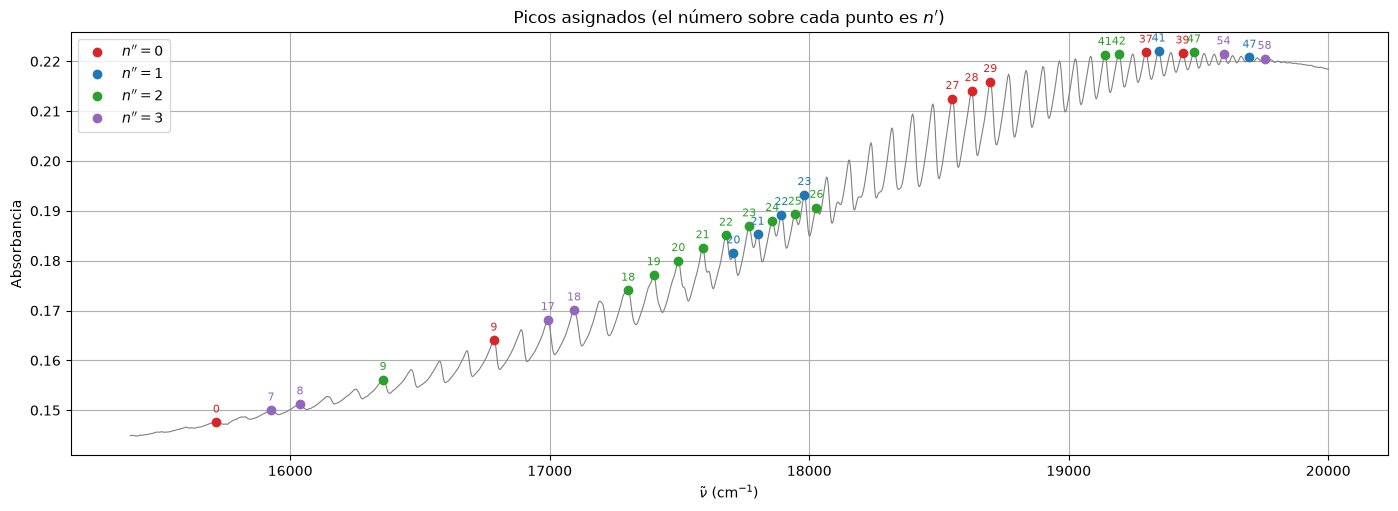

In [10]:
colores = ["tab:red", "tab:blue", "tab:green", "tab:purple"]
fig, ax = plt.subplots(figsize=(17, 5.5))
ax.plot(1e7 / l25, A25, color="gray", lw=0.8)
for k in range(NMAX + 1):
    s = asig25[asig25[:, 2] == k]
    ax.plot(s[:, 0], np.interp(1e7 / s[:, 0], l25, A25), "o", color=colores[k], label=f"$n''={k}$")
    for v, n1 in zip(s[:, 0], s[:, 1]):
        ax.annotate(int(n1), (v, np.interp(1e7 / v, l25, A25)), textcoords="offset points", xytext=(0, 7),
                    ha="center", fontsize=8, color=colores[k])
ax.set_xlabel(r"$\tilde\nu$ (cm$^{-1}$)"); ax.set_ylabel("Absorbancia"); ax.grid(True)
ax.set_title("Picos asignados (el número sobre cada punto es $n'$)")
ax.legend()
plt.show()

Se asignaron 32 de los 60 picos (por serie $n''=0,1,2,3$: 7, 6, 13 y 6 líneas), con una dispersión de residuos de 3.6 cm$^{-1}$. Observaciones:

- Los picos **descartados** son sobre todo los más intensos, entre 520 y 555 nm, justo donde las series se superponen (candidatas a menos de `MARGEN` entre sí). Asignarlos a la fuerza metería errores de etiqueta ($n'$, $n''$) que sesgan los $a(n'')$; abajo se prueba cuánto depende el resultado de este criterio.
- La dispersión de 3.6 cm$^{-1}$ es mayor que lo que se esperaría sólo del error de posición. Probablemente se deba a que, cuando dos líneas están a ~10 cm$^{-1}$, el equipo (0.5 nm ≈ 15 cm$^{-1}$) no las separa y el máximo queda en una posición intermedia, y a que el máximo observado de cada banda no es exactamente su origen (estructura rotacional sin resolver). Se aprecia en el gráfico de residuos más abajo.
- En $\lambda > 590$ nm las líneas asignadas son casi todas de $n''\ge 2$. Es consistente con que desde $n''=0$ el solapamiento hacia $n'$ bajos es pequeño (el mínimo de B está desplazado respecto del de X), y las bandas calientes dominan ahí; es una interpretación, no algo que se haya verificado con intensidades.

# (A) Series libres: $a(n'')$, $b$ y $c$

Ajuste de $\tilde\nu = a(n'') + b(n'+\frac12) + c(n'+\frac12)^2$ con un $a$ por serie y $b$, $c$ comunes. Las incertezas son las del ajuste, escaladas con la dispersión real de los residuos ($s^2=\sum r^2/(N-p)$).

In [11]:
solA, covA = ajuste_series(asig25)
nombres = [f"a(n''={k}) (cm-1)" for k in range(NMAX + 1)] + ["b = w' (cm-1)", "c = -w'x' (cm-1)"]
tabla_A = pd.DataFrame({"valor": solA, "error": np.sqrt(np.diag(covA))}, index=nombres)
tabla_A["lineas"] = n_por_serie + [len(asig25)] * 2
tabla_A.round(3)

,valor,error,lineas
a(n''=0) (cm-1),15654.230,2.899,7
a(n''=1) (cm-1),15442.473,3.276,6
a(n''=2) (cm-1),15228.975,3.016,13
a(n''=3) (cm-1),15019.785,2.465,6
b = w' (cm-1),126.390,0.203,32
c = -w'x' (cm-1),-0.777,0.003,32


In [12]:
# De a(0), a(1), a(2): a(n'') = nu_el - w''(n''+1/2) + wx''(n''+1/2)^2  =>  dos diferencias determinan w'' y wx''
def desde_a(a):
    wx2 = ((a[..., 2] - a[..., 1]) - (a[..., 1] - a[..., 0])) / 2
    w2 = -(a[..., 1] - a[..., 0]) + 2 * wx2
    nu_el = a[..., 0] + w2 / 2 - wx2 / 4
    return nu_el, w2, wx2

rng = np.random.default_rng(0)
mA = rng.multivariate_normal(solA, covA, size=100000)
valA, mcA = desde_a(solA), desde_a(mA[:, :NMAX + 1])
pd.DataFrame({"valor": valA, "error (MC)": [np.std(x) for x in mcA]}, index=["nu_el (cm-1)", "w'' (cm-1)", "w''x'' (cm-1)"]).round(3)

,valor,error (MC)
nu_el (cm-1),15759.456,3.877
w'' (cm-1),210.017,5.386
w''x'' (cm-1),-0.870,1.727


De $a(0), a(1), a(2)$ salen $\omega''$ y $\omega''x''$ de la forma exacta que indica la guía, pero $\omega''x''$ es una **segunda diferencia** de cantidades con error de unos 3 cm$^{-1}$ cada una, así que su incerteza es mayor que el valor mismo. Es esperable: la anarmonicidad del estado fundamental ($\omega''x''\approx 0.6$ cm$^{-1}$) mueve los niveles muy por debajo de la resolución. Por eso, para los parámetros de Morse se usa el modelo global (B).

# (B) Modelo global de Morse y sensibilidad a la asignación

Se ajustan directamente $\tilde\nu_{el}$, $\omega''$, $\omega''x''$, $\omega'$ y $\omega'x'$ a todas las líneas. La incerteza estadística sale del ajuste (escalada con los residuos), pero la dominante es la **elección de la asignación** (`NMAX` y `MARGEN`): se repite el análisis con otras 5 configuraciones y se toma como incerteza sistemática la mitad del rango de cada parámetro; la total es la suma en cuadratura.

In [13]:
configs = [(nmax, margen) for nmax in (2, 3) for margen in (6.0, 3.0, 0.0)]
nom_p = ["nu_el", "w''", "w''x''", "w'", "w'x'"]
filas_s = []
for nmax, margen in configs:
    R = iterar(nu_pk, nmax=nmax, margen=margen)
    filas_s.append({"NMAX": nmax, "MARGEN": margen, "líneas": len(R["asig"]), "s (cm-1)": R["s"], **dict(zip(nom_p, R["p"]))})
sens = pd.DataFrame(filas_s)
sens.round(3)

,NMAX,MARGEN,líneas,s (cm-1),nu_el,w'',w''x'',w',w'x'
0,2,6.0,37,4.923,15764.705,212.829,0.481,125.757,0.766
1,2,3.0,45,5.401,15767.246,216.893,1.249,125.867,0.767
2,2,0.0,49,5.322,15762.635,210.641,-0.376,125.751,0.764
3,3,6.0,32,3.621,15761.938,214.747,0.746,126.369,0.777
4,3,3.0,45,4.777,15764.262,218.743,1.896,126.337,0.777
5,3,0.0,52,4.718,15766.946,215.018,0.851,125.955,0.771


In [14]:
sist = (sens[nom_p].max() - sens[nom_p].min()).to_numpy() / 2        # incerteza sistemática por la asignación
est = np.sqrt(np.diag(R25["cov"]))
tot = np.sqrt(est**2 + sist**2)
lit = np.array([15769.01, 214.50, 0.607, 125.69, 0.764])            # Huber-Herzberg / NIST

tabla_B = pd.DataFrame({
    "valor": R25["p"], "err estadístico": est, "err sistemático": sist, "err total": tot,
    "literatura": lit, "dif. rel. (%)": 100 * (R25["p"] - lit) / lit, "|dif|/err total": np.abs(R25["p"] - lit) / tot,
}, index=["nu_el (cm-1)", "w'' (cm-1)", "w''x'' (cm-1)", "w' (cm-1)", "w'x' (cm-1)"])
tabla_B.round(3)

,valor,err estadístico,err sistemático,err total,literatura,dif. rel. (%),|dif|/err total
nu_el (cm-1),15761.938,3.060,2.654,4.051,15769.010,-0.045,1.746
w'' (cm-1),214.747,2.882,4.051,4.971,214.500,0.115,0.050
w''x'' (cm-1),0.746,0.749,1.136,1.361,0.607,22.894,0.102
w' (cm-1),126.369,0.202,0.309,0.369,125.690,0.540,1.838
w'x' (cm-1),0.777,0.003,0.006,0.007,0.764,1.661,1.760


# Parámetros de Morse de los estados X y B

Para cada estado, con $\mu = m_I/2$:
$$D_e = \frac{\omega^2}{4\,\omega x},\qquad D_0 = D_e - \tfrac{\omega}{2} + \tfrac{\omega x}{4},\qquad k=\mu\,(2\pi c\,\omega)^2 = 2D_e\alpha^2 \;\Rightarrow\; \alpha=\sqrt{k/2D_e}.$$
La incerteza se propaga por Monte Carlo, muestreando los 5 parámetros de una normal con covarianza = (ajuste) + (sistemática, diagonal). Las muestras con $\omega x\le 0$ no tienen $D_e$ y se descartan (se informa la fracción válida).

In [15]:
c_luz = 2.99792458e10      # cm/s
h = 6.62607015e-34         # J s
u = 1.66053907e-27         # kg
mu = 126.90447 * u / 2     # masa reducida del I2 (kg)
eV_por_cm = 1.239842e-4

def morse(w, wx):
    # w, wx en cm-1 -> De, D0 (cm-1), k (N/m), alpha (1/Angstrom); NaN si wx <= 0
    wx = np.where(wx > 0, wx, np.nan)
    with np.errstate(invalid="ignore", divide="ignore"):
        De = w**2 / (4 * wx)
        D0 = De - w / 2 + wx / 4
        k = mu * (2 * np.pi * c_luz * w) ** 2
        alpha = np.sqrt(k / (2 * h * c_luz * De)) * 1e-10
    return De, D0, k, alpha

def derivados(p):
    p = np.asarray(p, dtype=float)
    nu_el, w2, wx2, w1, wx1 = (p[..., i] for i in range(5))
    return {"De'' (cm-1)": morse(w2, wx2)[0], "D0'' (cm-1)": morse(w2, wx2)[1], "k'' (N/m)": morse(w2, wx2)[2], "alpha'' (1/A)": morse(w2, wx2)[3],
            "De' (cm-1)": morse(w1, wx1)[0], "D0' (cm-1)": morse(w1, wx1)[1], "k' (N/m)": morse(w1, wx1)[2], "alpha' (1/A)": morse(w1, wx1)[3]}

cov_tot = R25["cov"] + np.diag(sist**2)
mB = rng.multivariate_normal(R25["p"], cov_tot, size=200000)
valB, mcB = derivados(R25["p"]), derivados(mB)
print(f"fracción de muestras MC con w''x'' > 0: {np.mean(mB[:, 2] > 0):.2f};  con w'x' > 0: {np.mean(mB[:, 4] > 0):.2f}")

# valor central + percentiles 16 y 84 de la distribución MC (la de De'' es muy asimétrica: wx'' tiene un error comparable a su valor)
pd.DataFrame({"valor": {k: float(v) for k, v in valB.items()},
              "p16 (MC)": {k: float(np.nanpercentile(v, 16)) for k, v in mcB.items()},
              "p84 (MC)": {k: float(np.nanpercentile(v, 84)) for k, v in mcB.items()}}).round(3)

fracción de muestras MC con w''x'' > 0: 0.71;  con w'x' > 0: 1.00


,valor,p16 (MC),p84 (MC)
De'' (cm-1),15455.282,4917.671,27381.663
D0'' (cm-1),15348.095,4810.154,27277.367
k'' (N/m),172.406,164.556,180.432
alpha'' (1/A),1.676,1.256,2.995
De' (cm-1),5140.089,5090.854,5190.093
D0' (cm-1),5077.099,5027.935,5127.033
k' (N/m),59.700,59.355,60.049
alpha' (1/A),1.710,1.702,1.718


**Lectura.**

- **Estado B:** $\omega' = 126.4 \pm 0.4$ cm$^{-1}$ y $\omega' x' = 0.777 \pm 0.007$ cm$^{-1}$, a 1.8 desvíos de la literatura (125.69 y 0.764). Con ellos $D_e' \approx 5140 \pm 50$ cm$^{-1}$, $k' \approx 59.7 \pm 0.4$ N/m y $\alpha' \approx 1.71$ Å$^{-1}$. La fracción de muestras MC con $\omega' x' > 0$ es 1: el estado B queda bien determinado.
- **Estado X:** $\omega'' = 214.7 \pm 5.0$ cm$^{-1}$ (literatura 214.50) y $k'' \approx 172 \pm 8$ N/m, que sólo depende de $\omega''$. En cambio $\omega'' x'' = 0.7 \pm 1.4$ cm$^{-1}$ es compatible con la literatura (0.607) **pero también con cero**: su incerteza es mayor que el valor. Por eso $D_e''$ y $\alpha''$ **no están determinados** por estos datos (sólo 71 % de las muestras MC tienen $\omega''x''>0$ y los percentiles de $D_e''$ se van a valores enormes). El potencial de X que se grafica abajo usa el valor central y sólo es ilustrativo.
- $\tilde\nu_{el} = 15762 \pm 4$ cm$^{-1}$ (literatura 15769). Los $D_e$ son extrapolaciones: la fórmula $D_e=\omega^2/4\omega x$ supone que la Morse describe todo el pozo.

# Gráficos de la progresión y de los potenciales

Para ver el ajuste se grafica $\tilde\nu - [\tilde\nu_{el} - G''(n'')]$ (que debería ser $G'(n')$) en función de $n'+\tfrac12$: todas las series deben caer sobre la misma parábola.

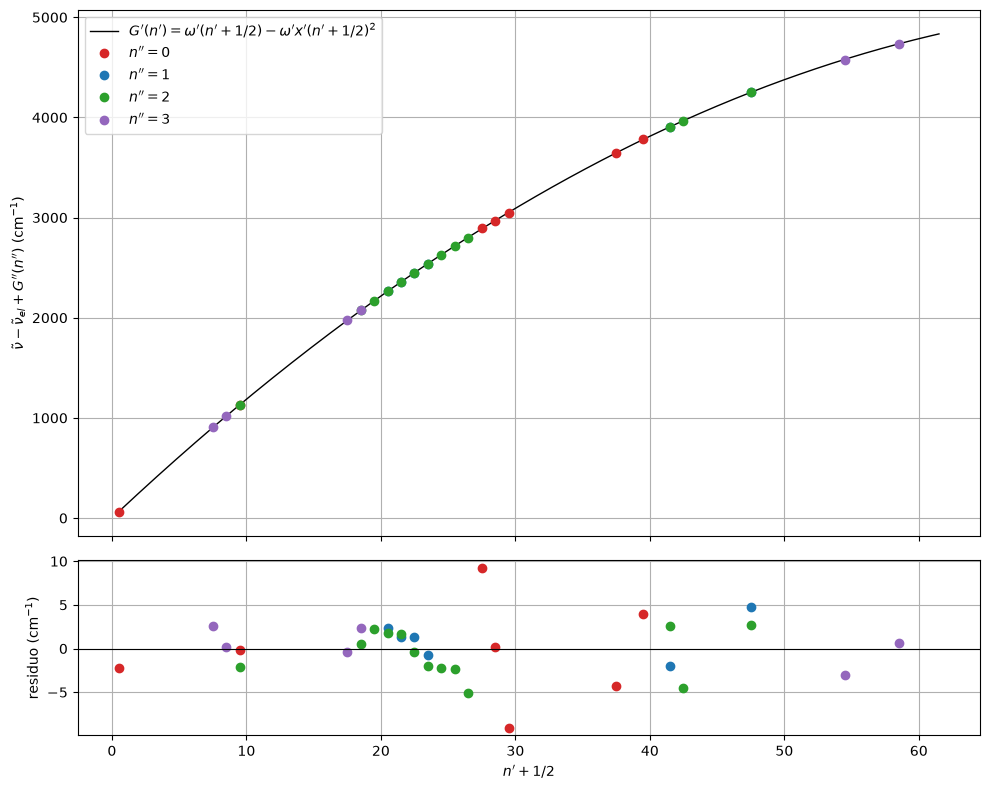

In [16]:
p = R25["p"]
fig, axs = plt.subplots(2, 1, figsize=(10, 8), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
x = np.linspace(0, asig25[:, 1].max() + 3, 300)
axs[0].plot(x + 0.5, G(x, p[3], p[4]), "k-", lw=1, label=r"$G'(n')=\omega'(n'+1/2)-\omega'x'(n'+1/2)^2$")
for k in range(NMAX + 1):
    m = asig25[:, 2] == k
    s = asig25[m]
    axs[0].plot(s[:, 1] + 0.5, s[:, 0] - (p[0] - G(k, p[1], p[2])), "o", color=colores[k], label=f"$n''={k}$")
    axs[1].plot(s[:, 1] + 0.5, res25[m], "o", color=colores[k])
axs[1].axhline(0, color="k", lw=0.8)
axs[0].set_ylabel(r"$\tilde\nu - \tilde\nu_{el} + G''(n'')$ (cm$^{-1}$)"); axs[1].set_ylabel("residuo (cm$^{-1}$)")
axs[1].set_xlabel(r"$n'+1/2$")
for ax in axs:
    ax.grid(True)
axs[0].legend()
plt.tight_layout()
plt.show()

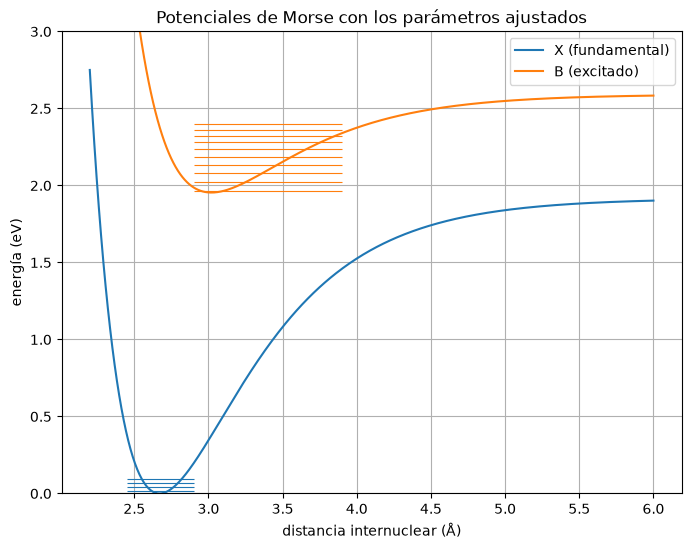

In [17]:
# Potenciales de Morse. Los parámetros de energía salen del ajuste; la distancia de equilibrio no se mide en este experimento:
# para X se usa 2.67 A (diapo de la clase) y para B 3.02 A (literatura), sólo para ubicar las curvas en r.
r = np.linspace(2.2, 6.0, 500)
De_X, al_X = valB["De'' (cm-1)"], valB["alpha'' (1/A)"]
De_B, al_B = valB["De' (cm-1)"], valB["alpha' (1/A)"]
V_X = De_X * (1 - np.exp(-al_X * (r - 2.67))) ** 2
V_B = p[0] + De_B * (1 - np.exp(-al_B * (r - 3.02))) ** 2

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(r, V_X * eV_por_cm, label="X (fundamental)")
ax.plot(r, V_B * eV_por_cm, label="B (excitado)")
for k in range(4):
    ax.hlines(G(k, p[1], p[2]) * eV_por_cm, 2.45, 2.9, color="tab:blue", lw=0.8)
for n1 in range(0, 40, 4):
    ax.hlines((p[0] + G(n1, p[3], p[4])) * eV_por_cm, 2.9, 3.9, color="tab:orange", lw=0.8)
ax.set_xlabel("distancia internuclear (Å)"); ax.set_ylabel("energía (eV)"); ax.set_ylim(0, 3)
ax.grid(True); ax.legend()
ax.set_title("Potenciales de Morse con los parámetros ajustados")
plt.show()

# Verificación con el segundo conjunto de datos (`BR`, 2022)

Se repite el mismo procedimiento (mismo filtro, mismos parámetros de asignación, mismo rango $\lambda\le650$ nm) sobre el espectro `BR`, medido otro día con paso de 0.05 nm. Comparar ambos muestra cuánto cambian los parámetros por el conjunto de datos y no por el ajuste.

In [18]:
lBR = alta["lambda"].to_numpy(); ABR = alta["A"].to_numpy()
FBR, lam_BR, nu_BR, prom_BR = detectar_picos(lBR, ABR)
RBR = iterar(nu_BR)
print(f"BR: {len(RBR['asig'])} de {len(nu_BR)} picos asignados; por serie: {[int((RBR['asig'][:, 2] == k).sum()) for k in range(NMAX + 1)]}; s = {RBR['s']:.2f} cm-1")

comp = pd.DataFrame({
    "2025": R25["p"], "err 2025": np.sqrt(np.diag(R25["cov"])),
    "BR 2022": RBR["p"], "err BR": np.sqrt(np.diag(RBR["cov"])),
}, index=tabla_B.index)
comp["dif. (cm-1)"] = comp["BR 2022"] - comp["2025"]
comp["dif./err"] = comp["dif. (cm-1)"] / np.hypot(comp["err 2025"], comp["err BR"])
comp.round(3)

BR: 30 de 52 picos asignados; por serie: [7, 6, 12, 5]; s = 3.93 cm-1


,2025,err 2025,BR 2022,err BR,dif. (cm-1),dif./err
nu_el (cm-1),15761.938,3.060,15760.200,4.527,-1.739,-0.318
w'' (cm-1),214.747,2.882,214.769,2.988,0.022,0.005
w''x'' (cm-1),0.746,0.749,0.621,0.774,-0.125,-0.116
w' (cm-1),126.369,0.202,127.061,0.322,0.692,1.819
w'x' (cm-1),0.777,0.003,0.795,0.006,0.018,2.640


In [19]:
# Comparación con el dato de la diapo: Lambda(0->24) = 548.33 nm
nu_24_0 = modelo(R25["p"], 24, 0)
print(f"modelo ajustado: (n'=24, n''=0) en {1e7 / nu_24_0:.2f} nm = {nu_24_0:.1f} cm-1;  diapo: 548.33 nm = {1e7 / 548.33:.1f} cm-1")
vecinos = lam_pk[np.argsort(np.abs(lam_pk - 1e7 / nu_24_0))[:3]]
print("picos medidos más cercanos (nm):", np.round(np.sort(vecinos), 2))

modelo ajustado: (n'=24, n''=0) en 546.91 nm = 18284.6 cm-1;  diapo: 548.33 nm = 18237.2 cm-1
picos medidos más cercanos (nm): [543.53 545.88 548.31]


# Conclusiones y puntos abiertos

- **Qué sale bien:** del espectro de 2025 se obtienen $\omega'$, $\omega'x'$ ($b$ y $c$ de la guía), $\omega''$ y $\tilde\nu_{el}$, todos a menos de 2 desvíos de la literatura. Los dos conjuntos de datos (2025 y `BR` de 2022) dan el mismo $\omega''$ (214.75 y 214.77 cm$^{-1}$) y $\tilde\nu_{el}$ compatibles.
- **Qué no sale:** $\omega''x''$ (y con él $D_e''$ y $\alpha''$ de X). La anarmonicidad del estado fundamental es demasiado chica frente a la resolución y a la superposición de series.
- **Diferencia entre conjuntos de datos:** $\omega'$ y $\omega'x'$ difieren 0.7 cm$^{-1}$ y 0.018 cm$^{-1}$ entre 2025 y `BR` (1.8 y 2.6 desvíos de las incertezas estadísticas) y ambos dan $\omega'$ por encima de la literatura. Hay un sesgo sistemático (asignación, máximos de banda vs orígenes) que las incertezas estadísticas no cubren del todo.
- **Punto a consultar:** la diapo de la clase da $\Lambda_{0\to24}=548.33$ nm. En nuestros datos hay un pico a 548.3 nm, pero en el modelo ajustado la transición (24, 0) cae donde indica la celda de arriba (≈ 547 nm), a unos 47 cm$^{-1}$ del pico medido (más de la mitad de la separación entre líneas, ≈ 80 cm$^{-1}$). No se resolvió si es una cuestión de convención de numeración o si ese pico es otra transición.
- **Limitaciones:** una sola medición por conjunto, sin medición de línea base del equipo, sin corregir la pendiente de la línea base (≈ −3 cm$^{-1}$ en las posiciones) y con la asignación arrancando de valores de la literatura.